# 06 Model Comparison

Bayesian comparison between:

- Single Sérsic model
- Double Sérsic model

The mock galaxy is generated from a DoubleSersicModel and fitted with both models.
The comparison is performed using the Dynesty Bayesian evidence.


In [1]:
from baymorph import (
    ConvolvedModel,
    DoubleSersicModel,
    DynestyFitter,
    GaussianPSF,
    Parameter,
    ParameterSet,
    SersicModel,
    add_gaussian_noise,
    make_constant_noise_map,
    show_log_image,
)

import numpy as np

## Generate true double-Sérsic galaxy

In [2]:
bulge = SersicModel(
    flux=3000,
    re=6,
    n=4,
    q=0.8,
    theta=0.0,
    x0=30,
    y0=30,
)

disk = SersicModel(
    flux=7000,
    re=12,
    n=1,
    q=0.8,
    theta=0.0,
    x0=30,
    y0=30,
)

true_model = DoubleSersicModel(
    bulge=bulge,
    disk=disk,
)

In [3]:
psf = GaussianPSF(
    fwhm=3.0,
)

true_model = ConvolvedModel(
    true_model,
    psf,
)

In [4]:
clean_image = true_model.render(
    shape=(60, 60),
)

data = add_gaussian_noise(
    clean_image,
    sigma=1.0,
    seed=42,
)

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

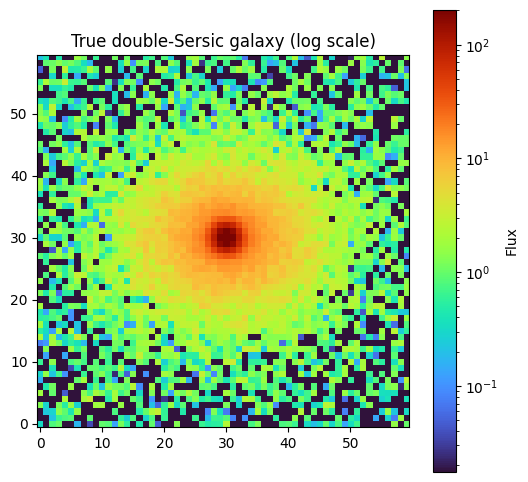

In [5]:
show_log_image(
    data,
    title="True double-Sersic galaxy",
)

## Single Sérsic fit

In [6]:
def single_model_factory(
    flux,
    re,
    n,
):
    model = SersicModel(
        flux=flux,
        re=re,
        n=n,
        q=0.8,
        theta=0.0,
        x0=30,
        y0=30,
    )

    return ConvolvedModel(
        model,
        psf,
    )

In [7]:
single_parameters = ParameterSet(
    [
        Parameter(
            "flux",
            1000,
            15000,
        ),
        Parameter(
            "re",
            1,
            25,
        ),
        Parameter(
            "n",
            0.5,
            8,
        ),
    ]
)

In [8]:
single_fitter = DynestyFitter(
    model_factory=single_model_factory,
    data=data,
    noise=noise,
    parameters=single_parameters,
)

In [9]:
single_result = single_fitter.run(
    nlive=150,
    sample="rwalk",
)

iter: 3087 | +150 | bound: 17 | nc: 1 | ncall: 64160 | eff(%):  5.057 | loglstar:   -inf < -5906.529 <    inf | logz: -5925.159 +/-  0.338 | dlogz:  0.001 >  0.159                                   

In [10]:
single_logz = single_result.logz[-1]

print(
    "Single Sérsic logZ:",
    single_logz,
)

Single Sérsic logZ: -5925.158609881601


## Double Sérsic fit

In [11]:
def double_model_factory(
    flux_bulge,
    re_bulge,
    flux_disk,
    re_disk,
):
    bulge = SersicModel(
        flux=flux_bulge,
        re=re_bulge,
        n=4,
        q=0.8,
        theta=0.0,
        x0=30,
        y0=30,
    )

    disk = SersicModel(
        flux=flux_disk,
        re=re_disk,
        n=1,
        q=0.8,
        theta=0.0,
        x0=30,
        y0=30,
    )

    model = DoubleSersicModel(
        bulge=bulge,
        disk=disk,
    )

    return ConvolvedModel(
        model,
        psf,
    )

In [12]:
double_parameters = ParameterSet(
    [
        Parameter(
            "flux_bulge",
            500,
            6000,
        ),
        Parameter(
            "re_bulge",
            1,
            8,
        ),
        Parameter(
            "flux_disk",
            3000,
            12000,
        ),
        Parameter(
            "re_disk",
            5,
            20,
        ),
    ]
)

In [13]:
double_fitter = DynestyFitter(
    model_factory=double_model_factory,
    data=data,
    noise=noise,
    parameters=double_parameters,
)

In [14]:
double_result = double_fitter.run(
    nlive=150,
    sample="rwalk",
)

iter: 2695 | +150 | bound: 16 | nc: 1 | ncall: 57886 | eff(%):  4.928 | loglstar:   -inf < -5108.033 <    inf | logz: -5124.063 +/-  0.311 | dlogz:  0.001 >  0.159                                   

In [15]:
double_logz = double_result.logz[-1]

print(
    "Double Sérsic logZ:",
    double_logz,
)

Double Sérsic logZ: -5124.0633398299


## Model comparison

In [16]:
delta_logz = (
    double_logz
    - single_logz
)

print(
    "ΔlogZ:",
    delta_logz,
)

ΔlogZ: 801.0952700517009


In [17]:
if delta_logz < 1:
    print(
        "Inconclusive"
    )

elif delta_logz < 3:
    print(
        "Weak evidence"
    )

elif delta_logz < 5:
    print(
        "Moderate evidence"
    )

else:
    print(
        "Strong evidence for Double Sérsic"
    )

Strong evidence for Double Sérsic


In [18]:
print(
    "BayMorph correctly prefers the generating model."
)

BayMorph correctly prefers the generating model.
